In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df_alunos = pd.read_csv("alunos_senai_sig.csv")

GRÁFICOS EM PIZA - porcentagem de alunos em cada turma

Curso
Banco de Dados    10
Design            15
Java              15
Python            20
dtype: int64


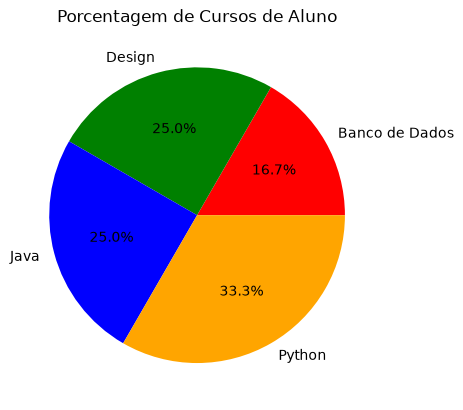

In [23]:
contagem_de_cursos = df_alunos.groupby('Curso').size()

print(contagem_de_cursos)

plt.pie(
    contagem_de_cursos,
        labels=contagem_de_cursos.index,
    autopct='%1.1f%%',
    colors=['red', 'green', 'blue', 'orange'],
)
plt.title("Porcentagem de Cursos de Aluno")
plt.show()

GRÁFICO DE MÉDIA DE CADA TURMA

Curso
Design            7.333333
Banco de Dados    7.130000
Java              6.966667
Python            6.115000
Name: Media_Final, dtype: float64


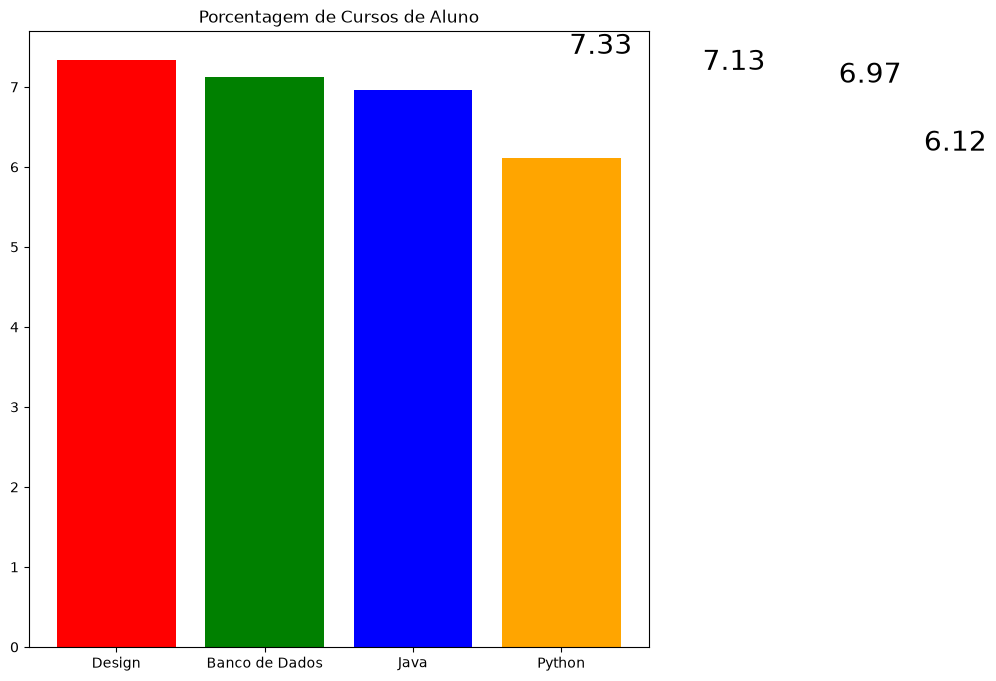

In [69]:
media_por_curso = df_alunos.groupby('Curso')["Media_Final"].mean().sort_values(ascending=False)

plt.figure(figsize = (8,8))


print(media_por_curso)
barra = plt.bar(
    media_por_curso.index,
    media_por_curso,
    color=['red', 'green', 'blue', 'orange'],
)

plt.title("Porcentagem de Cursos de Aluno")

for coluna in barra:
    yvalor = coluna.get_height().round(2)
    plt.text(
        coluna.get_x() + coluna.get_height()/2,
        yvalor,
        f'{yvalor:.2f}',
        fontsize=20,
        ha='center',
        va='bottom',


    )

plt.show()

MÉDIA DE NOTAS INDIVIDUAL POR ALUNOS DO CURSO

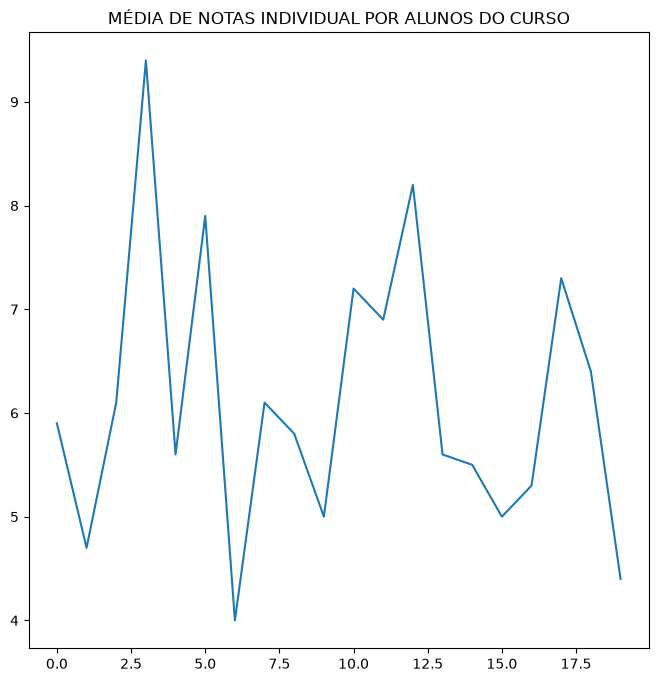

In [85]:
notas_python= df_alunos[
    df_alunos["Curso"] == "Python"
].reset_index(drop=True)

plt.figure(figsize = (8,8))

plt.plot(
    notas_python.index,
    notas_python["Media_Final"],
)

plt.title("MÉDIA DE NOTAS INDIVIDUAL POR ALUNOS DO CURSO")
plt.savefig("notas_python.png")

plt.show()

LIDANDO COM SUBPLOTS

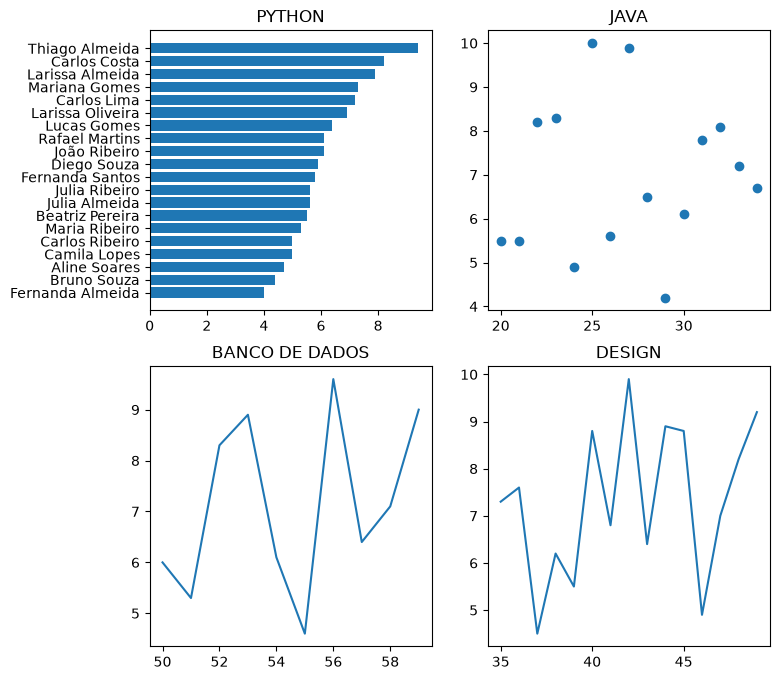

In [105]:
fig, axs = plt.subplots(2, 2, figsize = (8,8))
#[[0,0] [0,1]]
#[[1,0] [1,1]]

df_python= df_alunos[df_alunos["Curso"] == "Python"].sort_values(by=["Media_Final"])
df_java= df_alunos[df_alunos["Curso"] == "Java"]
df_bd= df_alunos[df_alunos["Curso"] == "Banco de Dados"]
df_design= df_alunos[df_alunos["Curso"] == "Design"]

axs[0,0].barh(df_python['Nome'],df_python["Media_Final"])
axs[0,0].set_title("PYTHON")
axs[0,1].scatter(df_java.index,df_java["Media_Final"])
axs[0,1].set_title("JAVA")
axs[1,0].plot(df_bd.index,df_bd["Media_Final"])
axs[1,0].set_title("BANCO DE DADOS")
axs[1,1].plot(df_design.index,df_design["Media_Final"])
axs[1,1].set_title("DESIGN")

fig.savefig("subplot.png")

plt.show()